Web Scraping

In [1]:
from bs4 import BeautifulSoup
import requests

In [2]:
url = "https://www.zomato.com/nagpur/restaurants"

headers = {
    "User-Agent": (
        "Mozilla/5.0 (Windows NT 10.0; Win64; x64) "
        "Chrome/131.0.0.0 Safari/537.36"
    ),
    "Accept-Language": "en-IN,en;q=0.9"
}

response = requests.get(url, headers=headers)

print("Status code:", response.status_code)

Status code: 200



    <!DOCTYPE html>
    <html>
      <head>
      <meta name="viewport" content="width=device-width, initial-scale=1">
      <meta http-equiv="origin-trial" content="AlzQB4E1/oglHqdi3yJM7/LiXc5vF9wjLPfK2cmvqF59C9TOh44HZQWA1ZRuztoJDiKyuqKVvl5WNnfkKKpEvw4AAABOeyJvcmlnaW4iOiJodHRwczovL3d3dy56b21hdG8uY29tOjQ0MyIsImZlYXR1cmUiOiJXZWJNQ1AiLCJleHBpcnkiOjE4MDYzNjQ4MDB9">
      <link rel="preconnect" href="https://googleads.g.doubleclick.net">
      <link rel="preconnect" href="https://jumbo.zomato.com">
      <link rel="dns-prefetch" href="https://accounts.google.com">
      <link rel="dns-prefetch" href="https://securepubads.g.doubleclick.net">
      <link rel="dns-prefetch" href="https://www.google-analytics.com">
      <link rel="dns-prefetch" href="https://www.googleadservices.com">
      <link rel="dns-prefetch" href="https://play.google.com">
      <link rel="dns-prefetch" href="https://bat.bing.com">
      <link rel="dns-prefetch" href="https://8391443.fls.doubleclick.net">
      
     
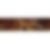
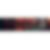
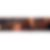
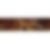
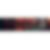
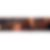

In [3]:
print(response.text)


<!DOCTYPE html>

<html>
<head>
<meta content="width=device-width, initial-scale=1" name="viewport"/>
<meta content="AlzQB4E1/oglHqdi3yJM7/LiXc5vF9wjLPfK2cmvqF59C9TOh44HZQWA1ZRuztoJDiKyuqKVvl5WNnfkKKpEvw4AAABOeyJvcmlnaW4iOiJodHRwczovL3d3dy56b21hdG8uY29tOjQ0MyIsImZlYXR1cmUiOiJXZWJNQ1AiLCJleHBpcnkiOjE4MDYzNjQ4MDB9" http-equiv="origin-trial"/>
<link href="https://googleads.g.doubleclick.net" rel="preconnect"/>
<link href="https://jumbo.zomato.com" rel="preconnect"/>
<link href="https://accounts.google.com" rel="dns-prefetch"/>
<link href="https://securepubads.g.doubleclick.net" rel="dns-prefetch"/>
<link href="https://www.google-analytics.com" rel="dns-prefetch"/>
<link href="https://www.googleadservices.com" rel="dns-prefetch"/>
<link href="https://play.google.com" rel="dns-prefetch"/>
<link href="https://bat.bing.com" rel="dns-prefetch"/>
<link href="https://8391443.fls.doubleclick.net" rel="dns-prefetch"/>
<link crossorigin="" href="https://b.zmtcdn.com" rel="preconnect"/>
<link as="fo
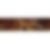
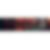
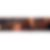
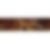
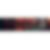
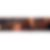

In [4]:
soup = BeautifulSoup(response.text, "html.parser")
print(soup)

<!DOCTYPE html>
<html>
 <head>
  <meta content="width=device-width, initial-scale=1" name="viewport"/>
  <meta content="AlzQB4E1/oglHqdi3yJM7/LiXc5vF9wjLPfK2cmvqF59C9TOh44HZQWA1ZRuztoJDiKyuqKVvl5WNnfkKKpEvw4AAABOeyJvcmlnaW4iOiJodHRwczovL3d3dy56b21hdG8uY29tOjQ0MyIsImZlYXR1cmUiOiJXZWJNQ1AiLCJleHBpcnkiOjE4MDYzNjQ4MDB9" http-equiv="origin-trial"/>
  <link href="https://googleads.g.doubleclick.net" rel="preconnect"/>
  <link href="https://jumbo.zomato.com" rel="preconnect"/>
  <link href="https://accounts.google.com" rel="dns-prefetch"/>
  <link href="https://securepubads.g.doubleclick.net" rel="dns-prefetch"/>
  <link href="https://www.google-analytics.com" rel="dns-prefetch"/>
  <link href="https://www.googleadservices.com" rel="dns-prefetch"/>
  <link href="https://play.google.com" rel="dns-prefetch"/>
  <link href="https://bat.bing.com" rel="dns-prefetch"/>
  <link href="https://8391443.fls.doubleclick.net" rel="dns-prefetch"/>
  <link crossorigin="" href="https://b.zmtcdn.com" rel="pre
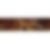
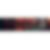
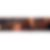
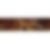
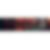
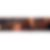

In [5]:
print(soup.prettify())

In [6]:
print(soup.title)

<title data-rh="true">The Best Restaurants in Nagpur for Dining Out </title>


In [7]:
print(soup.find("h1"))

<h1 class="sc-4rmu1c-0 sc-bIZIuE ibFUxF"> Restaurants in Nagpur</h1>


In [8]:
from bs4 import BeautifulSoup
import requests

restaurant_dict = {
    "name": [],
    "rating": [],
    "cuisine": [],
    "location": [],
    "cost_for_two": []
}

In [9]:
restaurant_names = soup.find_all("h4")

for name in restaurant_names:
    print(name.get_text(strip=True))

ARK Indian Kitchen
ACP Express Restaurant By Airport Centre Point
Bellavista Cafe & Skybar
Tipsy Turk
Slaps
Hotel President
Side Walk - Hotel Hardeo
TAO - Asian Kitchen
Marco's Pizza


In [10]:
import pandas as pd

df = pd.DataFrame(restaurant_dict)
df.to_csv("restaurant.csv", index=False)

print("CSV file saved successfully!")
df.head()

CSV file saved successfully!


,name,rating,cuisine,location,cost_for_two


EDA

In [11]:
df = pd.read_csv("enhanced_zomato_dataset_clean.csv")
df

,Restaurant_Name,Dining_Rating,Delivery_Rating,Dining_Votes,Delivery_Votes,Cuisine,Place_Name,City,Item_Name,Best_Seller,...,Is_Bestseller,Restaurant_Popularity,Avg_Rating_Restaurant,Avg_Price_Restaurant,Avg_Rating_Cuisine,Avg_Price_Cuisine,Avg_Rating_City,Avg_Price_City,Is_Highly_Rated,Is_Expensive
0,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Platter Kebab Combo,BESTSELLER,...,1,46,4.05,171.347826,3.818680,255.954894,3.939031,245.130482,1,0
1,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken Rumali Shawarma,BESTSELLER,...,1,46,4.05,171.347826,3.818680,255.954894,3.939031,245.130482,1,0
2,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken Tandoori Salad,NONE,...,1,46,4.05,171.347826,3.818680,255.954894,3.939031,245.130482,1,0
3,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken BBQ Salad,BESTSELLER,...,1,46,4.05,171.347826,3.818680,255.954894,3.939031,245.130482,1,0
4,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Special Doner Wrap Combo,MUST TRY,...,1,46,4.05,171.347826,3.818680,255.954894,3.939031,245.130482,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
123652,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Reshmi Kebab,NONE,...,1,286,4.05,354.475524,3.885698,208.939511,3.880503,194.591645,1,1
123653,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Large Tikka,NONE,...,1,286,4.05,354.475524,3.885698,208.939511,3.880503,194.591645,1,1
123654,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Chukandri Tikka,NONE,...,1,286,4.05,354.475524,3.885698,208.939511,3.880503,194.591645,1,1
123655,Ariena Boutique Hotel,3.9,4.2,13,523,Pizza,Purena,Raipur,Murgh Golden Kebab,NONE,...,1,286,4.05,354.475524,3.885698,208.939511,3.880503,194.591645,1,1


In [12]:
df.head()

,Restaurant_Name,Dining_Rating,Delivery_Rating,Dining_Votes,Delivery_Votes,Cuisine,Place_Name,City,Item_Name,Best_Seller,...,Is_Bestseller,Restaurant_Popularity,Avg_Rating_Restaurant,Avg_Price_Restaurant,Avg_Rating_Cuisine,Avg_Price_Cuisine,Avg_Rating_City,Avg_Price_City,Is_Highly_Rated,Is_Expensive
0,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Platter Kebab Combo,BESTSELLER,...,1,46,4.05,171.347826,3.81868,255.954894,3.939031,245.130482,1,0
1,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken Rumali Shawarma,BESTSELLER,...,1,46,4.05,171.347826,3.81868,255.954894,3.939031,245.130482,1,0
2,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken Tandoori Salad,NONE,...,1,46,4.05,171.347826,3.81868,255.954894,3.939031,245.130482,1,0
3,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Chicken BBQ Salad,BESTSELLER,...,1,46,4.05,171.347826,3.81868,255.954894,3.939031,245.130482,1,0
4,Doner King,3.9,4.2,39,0,Fast Food,Malakpet,Hyderabad,Special Doner Wrap Combo,MUST TRY,...,1,46,4.05,171.347826,3.81868,255.954894,3.939031,245.130482,1,0


In [13]:
df.shape

(123657, 26)

In [14]:
df.columns

Index(['Restaurant_Name', 'Dining_Rating', 'Delivery_Rating', 'Dining_Votes',
       'Delivery_Votes', 'Cuisine', 'Place_Name', 'City', 'Item_Name',
       'Best_Seller', 'Votes', 'Prices', 'Average_Rating', 'Total_Votes',
       'Price_per_Vote', 'Log_Price', 'Is_Bestseller', 'Restaurant_Popularity',
       'Avg_Rating_Restaurant', 'Avg_Price_Restaurant', 'Avg_Rating_Cuisine',
       'Avg_Price_Cuisine', 'Avg_Rating_City', 'Avg_Price_City',
       'Is_Highly_Rated', 'Is_Expensive'],
      dtype='object')

In [15]:
df.dtypes

,0
Restaurant_Name,object
Dining_Rating,float64
Delivery_Rating,float64
Dining_Votes,int64
Delivery_Votes,int64
Cuisine,object
Place_Name,object
City,object
Item_Name,object
Best_Seller,object


In [16]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 123657 entries, 0 to 123656
Data columns (total 26 columns):
 #   Column                 Non-Null Count   Dtype  
---  ------                 --------------   -----  
 0   Restaurant_Name        123657 non-null  object 
 1   Dining_Rating          123657 non-null  float64
 2   Delivery_Rating        123657 non-null  float64
 3   Dining_Votes           123657 non-null  int64  
 4   Delivery_Votes         123657 non-null  int64  
 5   Cuisine                123657 non-null  object 
 6   Place_Name             123657 non-null  object 
 7   City                   123657 non-null  object 
 8   Item_Name              123657 non-null  object 
 9   Best_Seller            123657 non-null  object 
 10  Votes                  123657 non-null  int64  
 11  Prices                 123657 non-null  float64
 12  Average_Rating         123657 non-null  float64
 13  Total_Votes            123657 non-null  int64  
 14  Price_per_Vote         123657 non-nu

In [17]:
df.describe()

,Dining_Rating,Delivery_Rating,Dining_Votes,Delivery_Votes,Votes,Prices,Average_Rating,Total_Votes,Price_per_Vote,Log_Price,Is_Bestseller,Restaurant_Popularity,Avg_Rating_Restaurant,Avg_Price_Restaurant,Avg_Rating_Cuisine,Avg_Price_Cuisine,Avg_Rating_City,Avg_Price_City,Is_Highly_Rated,Is_Expensive
count,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.0,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000,123657.000000
mean,3.822264,3.963184,152.729858,115.763725,24.666772,241.378399,3.892724,268.493583,154.707246,5.265611,1.0,304.008143,3.892724,241.378399,3.892724,241.378399,3.892724,241.378399,0.373970,0.243464
std,0.351407,0.244624,232.214061,243.970828,125.236009,192.830713,0.238449,292.811830,207.522162,0.699109,0.0,346.309371,0.229933,94.690020,0.074554,30.359509,0.025634,29.121965,0.483858,0.429174
min,2.500000,2.500000,0.000000,0.000000,0.000000,0.950000,3.000000,0.000000,0.006586,0.667829,1.0,4.000000,3.000000,35.833333,3.406122,61.428571,3.600000,194.591645,0.000000,0.000000
25%,3.700000,3.800000,0.000000,0.000000,0.000000,130.000000,3.750000,11.000000,11.000000,4.875197,1.0,125.000000,3.750000,178.460526,3.873352,212.572315,3.880503,223.676576,0.000000,0.000000
50%,3.822264,4.000000,30.000000,0.000000,0.000000,208.570000,3.911132,158.000000,95.000000,5.345058,1.0,195.000000,3.911132,230.959514,3.913401,254.565364,3.889413,235.550603,0.000000,0.000000
75%,4.000000,4.100000,217.000000,23.000000,15.000000,299.000000,4.050000,447.000000,245.000000,5.703782,1.0,318.000000,4.050000,285.146825,3.928624,255.954894,3.907014,245.130482,1.000000,0.000000
max,4.800000,4.600000,997.000000,983.000000,9750.000000,12024.000000,4.650000,1393.000000,12024.000000,9.394743,1.0,2059.000000,4.450000,1011.718750,4.250000,512.500000,4.000000,670.242424,1.000000,1.000000


In [18]:
df.isnull().sum()

,0
Restaurant_Name,0
Dining_Rating,0
Delivery_Rating,0
Dining_Votes,0
Delivery_Votes,0
Cuisine,0
Place_Name,0
City,0
Item_Name,0
Best_Seller,0


In [19]:
df.duplicated().sum()

np.int64(22127)

In [20]:
df.drop_duplicates(inplace = True)

In [21]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

print("Rows after removing duplicates:", len(df))


Rows after removing duplicates: 101530


In [22]:
df.sort_values(by = 'Avg_Rating_Restaurant')

,Restaurant_Name,Dining_Rating,Delivery_Rating,Dining_Votes,Delivery_Votes,Cuisine,Place_Name,City,Item_Name,Best_Seller,...,Is_Bestseller,Restaurant_Popularity,Avg_Rating_Restaurant,Avg_Price_Restaurant,Avg_Rating_Cuisine,Avg_Price_Cuisine,Avg_Rating_City,Avg_Price_City,Is_Highly_Rated,Is_Expensive
62043,Manchatti Restaurant,3.0,3.0,4,279,Desserts,Ernakulam City,Kochi,Strawberry Mojito,NONE,...,1,67,3.00,284.58209,3.963493,260.363492,3.869203,225.954220,0,0
62045,Manchatti Restaurant,3.0,3.0,4,279,Desserts,Ernakulam City,Kochi,Watermelon Mojito,NONE,...,1,67,3.00,284.58209,3.963493,260.363492,3.869203,225.954220,0,0
62011,Manchatti Restaurant,3.0,3.0,4,279,Desserts,Ernakulam City,Kochi,Egg Roast,NONE,...,1,67,3.00,284.58209,3.963493,260.363492,3.869203,225.954220,0,0
62014,Manchatti Restaurant,3.0,3.0,4,279,Desserts,Ernakulam City,Kochi,Konchu Perattu Curry,NONE,...,1,67,3.00,284.58209,3.963493,260.363492,3.869203,225.954220,0,1
62015,Manchatti Restaurant,3.0,3.0,4,279,Desserts,Ernakulam City,Kochi,Kozhi Perattu,NONE,...,1,67,3.00,284.58209,3.963493,260.363492,3.869203,225.954220,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
108587,Kings Kulfi,4.5,4.4,227,0,Shake,Rajinder Nagar,New Delhi,Mango Matka Kulfi+ Maharaja Kulfi,NONE,...,1,125,4.45,106.00800,3.913401,188.819633,3.943863,235.347676,1,0
108586,Kings Kulfi,4.5,4.4,227,0,Shake,Rajinder Nagar,New Delhi,Malai Matka Kulfi + Maharaja Kulfi,NONE,...,1,125,4.45,106.00800,3.913401,188.819633,3.943863,235.347676,1,0
108585,Kings Kulfi,4.5,4.4,227,0,Shake,Rajinder Nagar,New Delhi,Kesar Pista Matla Kulfi+ Maharaja Kulfi,NONE,...,1,125,4.45,106.00800,3.913401,188.819633,3.943863,235.347676,1,0
108584,Kings Kulfi,4.5,4.4,227,0,Shake,Rajinder Nagar,New Delhi,Dry Fruit Falooda + Maharaja Kulfi,NONE,...,1,125,4.45,106.00800,3.913401,188.819633,3.943863,235.347676,1,0


In [23]:
restaurant_df = df.drop_duplicates(
    subset=["Restaurant_Name", "City"]
).copy()

restaurant_dict = {
    "name": restaurant_df["Restaurant_Name"].tolist(),
    "rating": restaurant_df["Avg_Rating_Restaurant"].tolist(),
    "cuisine": restaurant_df["Cuisine"].tolist(),
    "location": restaurant_df["Place_Name"].tolist(),
    "city": restaurant_df["City"].tolist(),
    "price": restaurant_df["Avg_Price_Restaurant"].tolist(),
    "votes": restaurant_df["Dining_Votes"].tolist()
}

print("Total restaurant-city records:", len(restaurant_dict["name"]))

Total restaurant-city records: 907


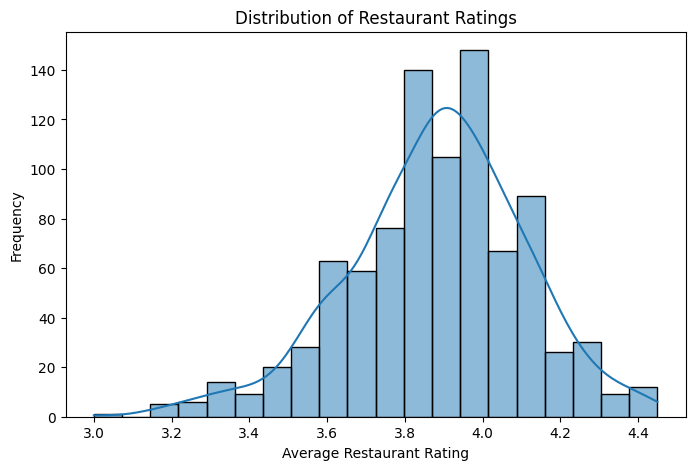

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Distribution of restaurant ratings

plt.figure(figsize=(8, 5))

sns.histplot(
    data=restaurant_df,
    x="Avg_Rating_Restaurant",
    bins=20,
    kde=True
)

plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Average Restaurant Rating")
plt.ylabel("Frequency")
plt.show()


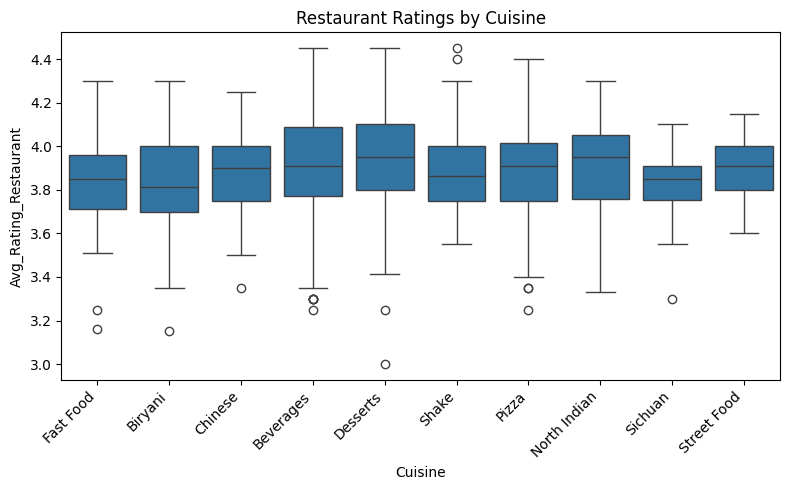

In [25]:
# 2. Ratings by popular cuisines

top_cuisines = (
    restaurant_df["Cuisine"]
    .value_counts()
    .head(10)
    .index
)

plt.figure(figsize=(8, 5))

sns.boxplot(
    data=restaurant_df[
        restaurant_df["Cuisine"].isin(top_cuisines)
    ],
    x="Cuisine",
    y="Avg_Rating_Restaurant"
)

plt.xticks(rotation=45, ha="right")
plt.title("Restaurant Ratings by Cuisine")
plt.tight_layout()
plt.show()



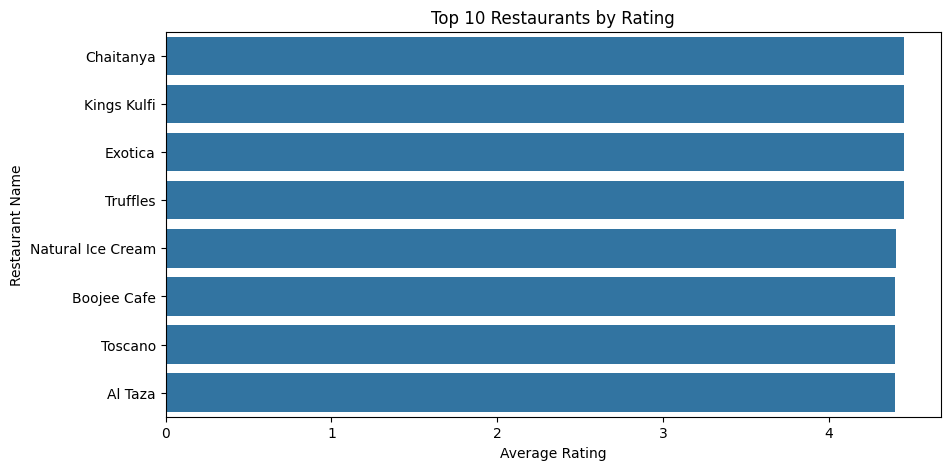

In [26]:
top10 = restaurant_df.nlargest(10, "Avg_Rating_Restaurant")

plt.figure(figsize=(10, 5))

sns.barplot(
    data=top10,
    x="Avg_Rating_Restaurant",
    y="Restaurant_Name"
)

plt.title("Top 10 Restaurants by Rating")
plt.xlabel("Average Rating")
plt.ylabel("Restaurant Name")
plt.show()

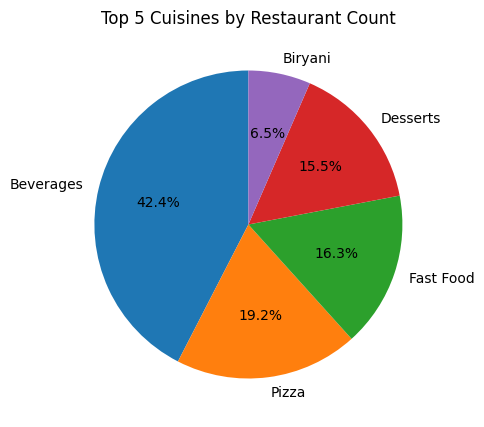

In [27]:
cuisine_counts = restaurant_df["Cuisine"].value_counts().head(5)

plt.figure(figsize=(5, 5))

plt.pie(
    cuisine_counts,
    labels=cuisine_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Top 5 Cuisines by Restaurant Count")
plt.show()

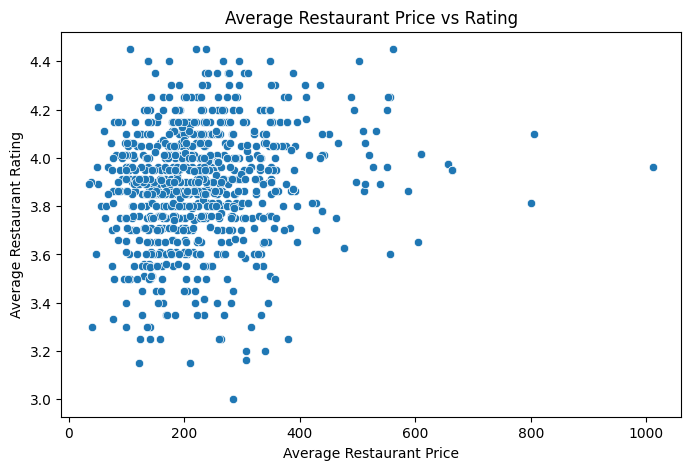

In [28]:
# 3. Restaurant price versus rating

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=restaurant_df,
    x="Avg_Price_Restaurant",
    y="Avg_Rating_Restaurant"
)

plt.title("Average Restaurant Price vs Rating")
plt.xlabel("Average Restaurant Price")
plt.ylabel("Average Restaurant Rating")
plt.show()

3. Samplings and distributions

In [29]:
# Prepare data for Practical 3

print("Total restaurants:", len(restaurant_df))

print("Average rating:",
      restaurant_df["Avg_Rating_Restaurant"].mean())

print("Median rating:",
      restaurant_df["Avg_Rating_Restaurant"].median())

print("Mode rating:",
      restaurant_df["Avg_Rating_Restaurant"].mode()[0])


print("Average price:",
      restaurant_df["Avg_Price_Restaurant"].mean())

print("Median price:",
      restaurant_df["Avg_Price_Restaurant"].median())

print("Mode price:",
      restaurant_df["Avg_Price_Restaurant"].mode()[0])


print("Average votes:",
      restaurant_df["Dining_Votes"].mean())

print("Median votes:",
      restaurant_df["Dining_Votes"].median())

print("Mode votes:",
      restaurant_df["Dining_Votes"].mode()[0])

Total restaurants: 907
Average rating: 3.8801873319819653
Median rating: 3.9
Mode rating: 4.0
Average price: 231.75349580815788
Median price: 216.2983870967742
Mode price: 254.63289940828403
Average votes: 113.17750826901874
Median votes: 11.0
Mode votes: 0


In [30]:
from scipy.stats import norm

ratings = restaurant_df["Avg_Rating_Restaurant"].dropna()

mean = ratings.mean()
std = ratings.std()

print("Mean:", mean)
print("Standard Deviation:", std)
print("Probability of rating below 4:",
      norm.cdf(4, mean, std))

Mean: 3.8801873319819653
Standard Deviation: 0.2300166268266834
Probability of rating below 4: 0.6987772499364038


In [31]:
from scipy.stats import binom

n = 10
p = 0.70

print("Probability of exactly 10 restaurants rated 4 or above:",
      binom.pmf(10, n, p))

Probability of exactly 10 restaurants rated 4 or above: 0.028247524899999984


In [32]:
from scipy.stats import poisson

average_votes = 5

print("Probability of exactly 3 votes:",
      poisson.pmf(3, average_votes))

Probability of exactly 3 votes: 0.1403738958142805


In [33]:
sample = restaurant_df.sample(n=50, random_state=42)

print(sample[["Restaurant_Name", "City",
              "Avg_Rating_Restaurant"]])

print("Sample size:", len(sample))

                            Restaurant_Name        City  Avg_Rating_Restaurant
118057                    Creams N Caffeine      Raipur               3.900000
59997                    Sijis Pizza Street       Kochi               3.950000
47988                        Firewood Pizza      Jaipur               3.561132
100965             Rominus Pizza And Burger     Lucknow               4.029266
106339                           Farzi Cafe   New Delhi               4.250000
113917                           Pizza Wala     Kolkata               3.761132
68661             A2B - Adyar Ananda Bhavan   Bangalore               3.851599
37148                               Toscano     Chennai               4.400000
123058  KGN Chicken Corner & Biryani Center      Raipur               3.400000
71930                             WOW! Momo     Kolkata               3.834537
71393                           Real Arabia       Kochi               3.750000
123324                        Dakshin Swaad      Rai

In [34]:
restaurant_df["Rating_Group"] = pd.cut(
    restaurant_df["Avg_Rating_Restaurant"],
    bins=[0, 2, 3, 4, 5],
    labels=["Low", "Average", "Good", "Excellent"],
    include_lowest=True
)

sample = restaurant_df.groupby(
    "Rating_Group", observed=True
).sample(frac=0.10, random_state=42)

print(sample[["Restaurant_Name", "Avg_Rating_Restaurant",
              "Rating_Group"]])

print("Sample size:", len(sample))

                          Restaurant_Name  Avg_Rating_Restaurant Rating_Group
121601                            Cafe 36               3.600000         Good
45308   Keventers - Milkshakes & Desserts               3.800000         Good
82688                        The Kebabish               3.750000         Good
83256                       Day 'N' Night               3.600000         Good
13409        Pista House - Premium Lounge               3.600000         Good
...                                   ...                    ...          ...
84190             1944 -The HOCCO Kitchen               4.300000    Excellent
13814                  Sherton Restaurant               4.100000    Excellent
123371              Ariena Boutique Hotel               4.050000    Excellent
116417             Manju Mamta Restaurant               4.200000    Excellent
23982      Speak Burgers by Vicky Ratnani               4.011132    Excellent

[91 rows x 3 columns]
Sample size: 91


In [35]:
sample = restaurant_df.iloc[::100]

print(sample[["Restaurant_Name", "City",
              "Avg_Rating_Restaurant"]])

print("Sample size:", len(sample))

              Restaurant_Name        City  Avg_Rating_Restaurant
0                  Doner King   Hyderabad               4.050000
12092      Late Night Biryani   Hyderabad               3.611132
27386                Anjappar     Chennai               3.450000
41250        Mother's Kitchen        Pune               4.000000
55010             Friedisthan      Jaipur               3.961132
65085   Joshis Masala Mantra         Goa               3.861132
82875           Prithvi Hotel   Ahmedabad               3.900000
96387        Lulu Hypermarket   Bangalore               3.900000
108749    Chili's Grill & Bar   New Delhi               4.300000
122804          Chai Govindam      Raipur               3.950000
Sample size: 10


In [36]:
def classify_rating(rating):
    if pd.isna(rating):
        return "Unknown"
    elif rating < 2:
        return "Low"
    elif rating < 3:
        return "Average"
    elif rating < 4:
        return "Good"
    else:
        return "Excellent"

restaurant_df["Rating_Category"] = restaurant_df[
    "Avg_Rating_Restaurant"
].apply(classify_rating)

print(restaurant_df[
    ["Restaurant_Name", "Avg_Rating_Restaurant",
     "Rating_Category"]
].head(10))

print("\nNumber of restaurants in each category:")
print(restaurant_df["Rating_Category"].value_counts())

                   Restaurant_Name  Avg_Rating_Restaurant Rating_Category
0                       Doner King               4.050000       Excellent
46                       Taco Bell               4.000000       Excellent
143                      BrownBear               3.800000            Good
178       Crystal Restaurant & Bar               4.050000       Excellent
409          Siddique Kabab Centre               4.250000       Excellent
456   Shah Ghouse Special Shawarma               4.200000       Excellent
723    Taj Mahal - Taj Mahal Hotel               4.100000       Excellent
832                    Burger King               3.928809            Good
1001                 Papadams Blue               3.950000            Good
1229               Ovenstory Pizza               4.030592       Excellent

Number of restaurants in each category:
Rating_Category
Good         607
Excellent    300
Name: count, dtype: int64


In [37]:
from scipy.stats import norm

ratings = restaurant_df["Avg_Rating_Restaurant"].dropna()

mean = ratings.mean()
std = ratings.std()

print("Mean:", mean)
print("Standard Deviation:", std)

print("CDF for rating 3:",
      norm.cdf(3, mean, std))

print("CDF for rating 4:",
      norm.cdf(4, mean, std))

Mean: 3.8801873319819653
Standard Deviation: 0.2300166268266834
CDF for rating 3: 6.495614568421637e-05
CDF for rating 4: 0.6987772499364038


In [38]:
import numpy as np

ratings = restaurant_df["Avg_Rating_Restaurant"].dropna()

# Population mean
population_mean = ratings.mean()
print("Population Mean:", population_mean)

# Take repeated random samples and calculate their means
sample_means = []

for i in range(1000):
    sample = ratings.sample(n=30, replace=True, random_state=i)
    sample_means.append(sample.mean())

# Mean of sample means
print("Mean of Sample Means:", np.mean(sample_means))

# Standard error
print("Standard Error:", np.std(sample_means, ddof=1))

# Display first 10 sample means
print("First 10 Sample Means:", sample_means[:10])

Population Mean: 3.8801873319819653
Mean of Sample Means: 3.878711624707172
Standard Error: 0.041312557230775794
First 10 Sample Means: [np.float64(3.9113221511756273), np.float64(3.8372411257885783), np.float64(3.744186062372433), np.float64(3.8454443134508964), np.float64(3.9578212691444823), np.float64(3.9117261153585487), np.float64(3.8841356933803017), np.float64(3.9124065526550735), np.float64(3.8915572102906184), np.float64(3.8710595535823944)]


In [39]:
from scipy import stats

confidence_level = 0.95
mean = df['Avg_Rating_Restaurant'].mean()
sem = stats.sem(df['Avg_Rating_Restaurant'])

confidence_interval = stats.t.interval(
confidence_level,
len(df)-1,
loc=mean,
scale=sem)
print("Confidence Interval:",confidence_interval)

Confidence Interval: (np.float64(3.8899904344336353), np.float64(3.8928194516967154))


In [40]:
rating = df['Avg_Rating_Restaurant']
t_stat , p_value = stats.ttest_1samp(rating, popmean = 50)
print("T-statistic:",t_stat)
print("P-value:",p_value)

alpha = 0.05
if p_value < alpha:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

T-statistic: -63889.50978111705
P-value: 0.0
Reject the null hypothesis.


In [41]:
mu = 70
#known population standard deviation
population_std = 70
# calculate sample mean and sample size
sample_mean = rating.mean()
n = len(rating)
#calculate Z statistics
z_score = (sample_mean - mu) / (population_std / np.sqrt(n))
#Calculate two-tailed p-value
p_value_z = 2 * (1 - stats.norm.cdf(np.abs(z_score)))

print("Z-score:",z_score)
print("P-value:",p_value_z)
#Decision
alpha = 0.05
if p_value_z < alpha:
    print("Reject the null hypothesis.")
else:
    print("Z-test on CSV data")

print("Fail to reject the null hypothesis.")

Z-score: -300.9241764763308
P-value: 0.0
Reject the null hypothesis.
Fail to reject the null hypothesis.


In [42]:
paired_data = restaurant_df[
    ["Dining_Rating", "Delivery_Rating"]
].dropna()

t_stat, p_value = stats.ttest_rel(
    paired_data["Dining_Rating"],
    paired_data["Delivery_Rating"]
)

print("T-statistic:", t_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the null hypothesis")
else:
    print("Fail to reject the null hypothesis")

T-statistic: -12.09734822624598
P-value: 2.4547777295443827e-31
Reject the null hypothesis


In [43]:
ratings = restaurant_df[
    ["Avg_Rating_Restaurant", "City"]
].dropna()

cities = ratings["City"].unique()

group1 = ratings[
    ratings["City"] == cities[0]
]["Avg_Rating_Restaurant"]

group2 = ratings[
    ratings["City"] == cities[1]
]["Avg_Rating_Restaurant"]

t_stat, p_value = stats.ttest_ind(
    group1, group2, equal_var=False
)

print("Group 1:", cities[0])
print("Group 2:", cities[1])
print("T-statistic:", t_stat)
print("P-value:", p_value)

Group 1:  Hyderabad
Group 2:  Mumbai
T-statistic: 0.38589368507691607
P-value: 0.7000558547494949


In [44]:
data = restaurant_df[
    ["City", "Avg_Rating_Restaurant"]
].dropna()

top_cities = data["City"].value_counts().head(3).index

groups = [
    data[data["City"] == city]["Avg_Rating_Restaurant"]
    for city in top_cities
]

f_stat, p_value = stats.f_oneway(*groups)

print("Cities:", list(top_cities))
print("F-statistic:", f_stat)
print("P-value:", p_value)

if p_value < 0.05:
    print("Significant difference between city mean ratings")
else:
    print("No significant difference found")

Cities: [' Hyderabad', ' Jaipur', ' Chennai']
F-statistic: 3.633426388613772
P-value: 0.027575783288200095
Significant difference between city mean ratings


In [45]:
from scipy.stats import chi2_contingency
data = restaurant_df[
    ["City", "Avg_Rating_Restaurant"]
].dropna().copy()

data["Rating_Category"] = pd.cut(
    data["Avg_Rating_Restaurant"],
    bins=[0, 2, 3, 4, 5],
    labels=["Low", "Average", "Good", "Excellent"],
    include_lowest=True
)

top_cities = data["City"].value_counts().head(5).index

data = data[data["City"].isin(top_cities)]

contingency_table = pd.crosstab(
    data["City"],
    data["Rating_Category"]
)

chi2, p_value, dof, expected = chi2_contingency(
    contingency_table
)

print("Contingency Table:")
print(contingency_table)
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("P-value:", p_value)

if p_value < 0.05:
    print("City and rating category are associated")
else:
    print("No significant association found")

Contingency Table:
Rating_Category  Good  Excellent
City                            
Bangalore          61         20
Chennai            63         24
Hyderabad          81         48
Jaipur             70         22
Mumbai             57         23
Chi-square statistic: 6.159169996303084
Degrees of freedom: 4
P-value: 0.18757252074421765
No significant association found


In [46]:
# Select numerical variables
data = restaurant_df[
    ["Avg_Rating_Restaurant",
     "Avg_Price_Restaurant",
     "Dining_Votes"]
]

# Calculate covariance matrix
covariance = data.cov()

print("Covariance Matrix:")
print(covariance)

Covariance Matrix:
                       Avg_Rating_Restaurant  Avg_Price_Restaurant  \
Avg_Rating_Restaurant               0.052908              3.580775   
Avg_Price_Restaurant                3.580775          11670.580032   
Dining_Votes                        9.122484            875.356179   

                       Dining_Votes  
Avg_Rating_Restaurant      9.122484  
Avg_Price_Restaurant     875.356179  
Dining_Votes           39993.333798  


In [47]:
# Calculate Pearson correlation matrix
pearson_corr = data.corr()

print("Pearson Correlation Matrix:")
print(pearson_corr)

Pearson Correlation Matrix:
                       Avg_Rating_Restaurant  Avg_Price_Restaurant  \
Avg_Rating_Restaurant               1.000000              0.144103   
Avg_Price_Restaurant                0.144103              1.000000   
Dining_Votes                        0.198317              0.040518   

                       Dining_Votes  
Avg_Rating_Restaurant      0.198317  
Avg_Price_Restaurant       0.040518  
Dining_Votes               1.000000  


In [48]:
# Calculate Spearman correlation matrix
spearman_corr = data.corr()

print("Spearman Correlation Matrix:")
print(spearman_corr)

Spearman Correlation Matrix:
                       Avg_Rating_Restaurant  Avg_Price_Restaurant  \
Avg_Rating_Restaurant               1.000000              0.144103   
Avg_Price_Restaurant                0.144103              1.000000   
Dining_Votes                        0.198317              0.040518   

                       Dining_Votes  
Avg_Rating_Restaurant      0.198317  
Avg_Price_Restaurant       0.040518  
Dining_Votes               1.000000  


In [49]:
#PEarson correlation hypothesis test
from scipy import stats

# Select the two variables and remove missing values
data = restaurant_df[
    ["Avg_Price_Restaurant", "Avg_Rating_Restaurant"]
].dropna()

x = data["Avg_Price_Restaurant"]
y = data["Avg_Rating_Restaurant"]

# Pearson correlation test
r, p_value = stats.pearsonr(x, y)

print("Pearson Correlation:", r)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the null hypothesis")
    print("There is a statistically significant linear correlation.")
else:
    print("Fail to reject the null hypothesis")
    print("There is insufficient no linear correlation.")

Pearson Correlation: 0.1441025162570863
P-value: 1.3208171973937423e-05
Reject the null hypothesis
There is a statistically significant linear correlation.


In [50]:
#Spearman correlation hypothesis test
from scipy import stats

# Select the two variables and remove missing values
data = restaurant_df[
    ["Dining_Votes", "Avg_Rating_Restaurant"]
].dropna()

x = data["Dining_Votes"]
y = data["Avg_Rating_Restaurant"]

# Spearman correlation test
rho, p_value = stats.spearmanr(x, y)

print("Spearman Correlation:", rho)
print("P-value:", p_value)

if p_value < 0.05:
    print("Reject the null hypothesis")
    print("There is a statistically significant monotonic relationship.")
else:
    print("Fail to reject the null hypothesis")
    print("There is no monotonic relationship.")

Spearman Correlation: 0.0167166337543322
P-value: 0.6151144797810552
Fail to reject the null hypothesis
There is no monotonic relationship.


In [52]:
# Feature Selection for Multiple Regression

features = [
    'Dining_Rating',
    'Delivery_Rating',
    'Dining_Votes',
    'Delivery_Votes',
    'Avg_Price_Restaurant'
]

X = restaurant_df[features].copy()
Y = restaurant_df['Avg_Rating_Restaurant'].copy()

# Remove rows with missing values in selected columns
valid_data = X.join(Y).dropna()
X = valid_data[features]
Y = valid_data['Avg_Rating_Restaurant']

print("Independent Variables:", features)
print("Dependent Variable: Avg_Rating_Restaurant")
print("Dataset shape:", X.shape)

Independent Variables: ['Dining_Rating', 'Delivery_Rating', 'Dining_Votes', 'Delivery_Votes', 'Avg_Price_Restaurant']
Dependent Variable: Avg_Rating_Restaurant
Dataset shape: (907, 5)


In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, random_state=42
)

print("Training sample:", len(X_train))
print("Testing sample:", len(X_test))

Training sample: 725
Testing sample: 182


In [54]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("X Train Scaled:")
print(X_train_scaled)

print("\nX Test Scaled:")
print(X_test_scaled)

X Train Scaled:
[[ 0.05028356  0.17765205 -0.56848807  0.29892073 -1.28626662]
 [ 0.57906747 -1.7068363   1.03899553 -0.54121976 -0.482585  ]
 [-1.50350895 -1.7068363  -0.44483548 -0.54121976 -0.62830921]
 ...
 [ 0.87657839  0.17765205  0.18331965 -0.54121976  0.24570014]
 [ 0.05028356 -0.57614329 -0.56848807  0.24471812  1.75443946]
 [-1.80101987  0.17765205 -0.36075172 -0.54121976 -0.60298781]]

X Test Scaled:
[[ 1.47160023e+00 -1.70683630e+00  5.04816365e-01 -5.41219763e-01
  -4.63927759e-01]
 [-1.59543638e-02  5.54549715e-01 -3.65697827e-01 -5.41219763e-01
   1.05420281e+00]
 [ 5.02835599e-02 -2.46063164e+00 -5.68488065e-01  6.97697098e-01
  -5.89245644e-01]
 [ 8.76578390e-01  5.54549715e-01  1.68481336e-01 -5.41219763e-01
   7.08897880e-01]
 [ 1.76911114e+00  5.54549715e-01 -5.68488065e-01  4.67797918e-03
   2.38000380e+00]
 [ 5.02835599e-02 -9.53040964e-01 -5.68488065e-01 -5.41219763e-01
   2.23330336e-03]
 [-1.20599804e+00  5.54549715e-01 -5.38811445e-01 -5.41219763e-01
  -5.017

In [55]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

# Multiple Linear Regression
linear_model = LinearRegression()
linear_model.fit(X_train_scaled, Y_train)

linear_pred = linear_model.predict(X_test_scaled)

print("Multiple Linear Regression")
print("=" * 40)
print("Intercept:", round(linear_model.intercept_, 4))
print("\nFeature Coefficients:")
for i in range(len(features)):
    print(features[i], ":", round(linear_model.coef_[i], 4))

Multiple Linear Regression
Intercept: 3.8795

Feature Coefficients:
Dining_Rating : 0.1533
Delivery_Rating : 0.1316
Dining_Votes : 0.0014
Delivery_Votes : -0.0027
Avg_Price_Restaurant : 0.002


In [56]:
ridge_model = Ridge(alpha=0.1)
ridge_model.fit(X_train_scaled, Y_train)
ridge_pred = ridge_model.predict(X_test_scaled)

print("Ridge Regression")
print("=" * 40)
print("Alpha:", ridge_model.alpha)
print("Intercept:", round(ridge_model.intercept_, 2))
print("Coefficient:", round(ridge_model.coef_[0], 2))

Ridge Regression
Alpha: 0.1
Intercept: 3.88
Coefficient: 0.15


In [58]:
lasso_model = Lasso(alpha=0.001, max_iter=20000)
lasso_model.fit(X_train_scaled, Y_train)
lasso_pred = lasso_model.predict(X_test_scaled)

print("Lasso Regression")
print("=" * 40)
print("Alpha:", lasso_model.alpha)
print("Intercept:", round(lasso_model.intercept_, 2))
print("Coefficient:", round(lasso_model.coef_[0], 2))

Lasso Regression
Alpha: 0.001
Intercept: 3.88
Coefficient: 0.15


In [59]:
tree_model = DecisionTreeRegressor(
    max_depth=10,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

tree_model.fit(X_train, Y_train)
tree_pred = tree_model.predict(X_test)

In [60]:
forest_model = RandomForestRegressor(
    n_estimators=300,
    max_depth=15,
    min_samples_split=5,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

forest_model.fit(X_train, Y_train)
forest_pred = forest_model.predict(X_test)

In [61]:
predictions = {
    'Linear Regression': linear_pred,
    'Ridge Regression': ridge_pred,
    'Lasso Regression': lasso_pred,
    'Decision Tree Regression': tree_pred,
    'Random Forest Regression': forest_pred
}

results = []

for model_name, pred in predictions.items():
    mae = mean_absolute_error(Y_test, pred)
    mse = mean_squared_error(Y_test, pred)
    rmse = np.sqrt(mse)
    r2 = r2_score(Y_test, pred)

    results.append([model_name, mae, mse, rmse, r2])

results_df = pd.DataFrame(
    results,
    columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2 Score']
)

print("Model Comparison:")
print(results_df.round(4).to_string(index=False))

Model Comparison:
                   Model    MAE    MSE   RMSE  R2 Score
       Linear Regression 0.0244 0.0027 0.0522    0.9501
        Ridge Regression 0.0244 0.0027 0.0522    0.9501
        Lasso Regression 0.0247 0.0027 0.0524    0.9499
Decision Tree Regression 0.0370 0.0042 0.0645    0.9239
Random Forest Regression 0.0287 0.0029 0.0536    0.9475


In [62]:
comparison = pd.DataFrame({
    'Restaurant_Price': X_test['Avg_Price_Restaurant'].values,
    'Actual_Rating': Y_test.values,
    'Linear_Regression_Pred': linear_pred,
    'Ridge_Regression_Pred': ridge_pred,
    'Lasso_Regression_Pred': lasso_pred,
    'Decision_Tree_Pred': tree_pred,
    'Random_Forest_Pred': forest_pred
})

comparison = comparison.sort_values(by='Restaurant_Price')

print("Actual vs Predicted Ratings:")
print(comparison.round(2).to_string(index=False))

Actual vs Predicted Ratings:
 Restaurant_Price  Actual_Rating  Linear_Regression_Pred  Ridge_Regression_Pred  Lasso_Regression_Pred  Decision_Tree_Pred  Random_Forest_Pred
            38.75           3.90                    3.91                   3.91                   3.91                3.89                3.90
            46.85           3.60                    3.60                   3.60                   3.61                3.63                3.63
            51.35           3.89                    3.89                   3.89                   3.89                3.89                3.89
            85.62           4.15                    4.14                   4.14                   4.14                4.15                4.15
            85.79           3.86                    3.98                   3.98                   3.98                3.96                3.96
            91.79           4.15                    4.14                   4.14                   4.14           

In [64]:
# Example restaurant input using all five features

new_restaurant = pd.DataFrame([{
    'Dining_Rating': 4.0,
    'Delivery_Rating': 4.1,
    'Dining_Votes': 100,
    'Delivery_Votes': 80,
    'Avg_Price_Restaurant': 500
}])

new_restaurant_scaled = scaler.transform(new_restaurant)

new_linear = linear_model.predict(new_restaurant_scaled)[0]
new_ridge = ridge_model.predict(new_restaurant_scaled)[0]
new_lasso = lasso_model.predict(new_restaurant_scaled)[0]

new_tree = tree_model.predict(new_restaurant)[0]
new_forest = forest_model.predict(new_restaurant)[0]

prediction_result = pd.DataFrame({
    'Model': [
        'Multiple Linear Regression',
        'Ridge Regression',
        'Lasso Regression',
        'Decision Tree Regression',
        'Random Forest Regression'
    ],
    'Predicted_Rating': [
        new_linear,
        new_ridge,
        new_lasso,
        new_tree,
        new_forest
    ]
})

print("Prediction for a New Restaurant")
print(prediction_result.round(3).to_string(index=False))

Prediction for a New Restaurant
                     Model  Predicted_Rating
Multiple Linear Regression             4.047
          Ridge Regression             4.047
          Lasso Regression             4.044
  Decision Tree Regression             4.015
  Random Forest Regression             4.014


In [65]:
models = {
    'Linear Regression': linear_model,
    'Ridge Regression': ridge_model,
    'Lasso Regression': lasso_model,
    'Decision Tree Regression': tree_model,
    'Random Forest Regression': forest_model
}

best_model_name = results_df.loc[
    results_df['R2 Score'].idxmax(), 'Model'
]

best_model = models[best_model_name]

print("Best Model:", best_model_name)
print("Best R2 Score:",
      round(results_df.loc[
          results_df['Model'] == best_model_name, 'R2 Score'
      ].iloc[0], 4))

Best Model: Ridge Regression
Best R2 Score: 0.9501


In [66]:
import joblib

joblib.dump(best_model, "best_restaurant_model.pkl")
joblib.dump(scaler, "restaurant_scaler.pkl")
joblib.dump(best_model_name, "best_restaurant_model_name.pkl")

print("Best model and scaler saved successfully.")

Best model and scaler saved successfully.


In [67]:
model = joblib.load("best_restaurant_model.pkl")
scaler = joblib.load("restaurant_scaler.pkl")
best_model_name = joblib.load("best_restaurant_model_name.pkl")

print("Loaded Model:", best_model_name)

Loaded Model: Ridge Regression


In [69]:
import gradio as gr
import pandas as pd

def predict_rating(dining_rating, delivery_rating,
                   dining_votes, delivery_votes, price):

    new_data = pd.DataFrame([{
        'Dining_Rating': dining_rating,
        'Delivery_Rating': delivery_rating,
        'Dining_Votes': dining_votes,
        'Delivery_Votes': delivery_votes,
        'Avg_Price_Restaurant': price
    }])

    if best_model_name in [
        'Decision Tree Regression',
        'Random Forest Regression'
    ]:
        prediction = model.predict(new_data)
    else:
        new_data_scaled = scaler.transform(new_data)
        prediction = model.predict(new_data_scaled)

    return round(float(prediction[0]), 2)


interface = gr.Interface(
    fn=predict_rating,
    inputs=[
        gr.Number(label="Dining Rating", value=4.0),
        gr.Number(label="Delivery Rating", value=4.0),
        gr.Number(label="Dining Votes", value=100),
        gr.Number(label="Delivery Votes", value=100),
        gr.Number(label="Average Restaurant Price (₹)", value=500)
    ],
    outputs=gr.Number(label="Predicted Restaurant Rating"),
    title="Restaurant Rating Prediction System",
    description="Enter restaurant details to predict its rating."
)

interface.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://4bb385c6d5f5ded318.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
